# 04 数据集、任务格式、划分和评价
本课把“数据集整理”落实为可操作实验：读取真实手写数字数据，检查标签与矩阵，拆分训练/验证/测试，构造基线并观察领域变化。
数据与模型指标都要对应明确任务，不能拿分类准确率代替检测/分割质量。


In [1]:
from pathlib import Path
import sys
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "course_utils.py").exists()), None)
if root is None:
    raise RuntimeError("请在完整的 cv-beginner-course 项目里打开 Notebook")
if str(root) not in sys.path: sys.path.insert(0, str(root))
from course_utils import setup, device, show_images, save_figure, ROOT
ROOT = setup(seed=42)
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch
print("计算设备:", device())


计算设备: cuda


## 1 输入：scikit-learn 内置手写数字
这是实际采集的 8×8 数字图，不需要联网。像素范围 0–16，标签为 0–9。
来源：[digits 数据文档](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)，UCI Optical Recognition of Handwritten Digits。


输入: (1797, 8, 8) 标签: (1797,) 范围: (np.float32(0.0), np.float32(16.0))
第一张图矩阵:
 [[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]
标签: 0


/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 26631 (\N{CJK UNIFIED IDEOGRAPH-6807}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 31614 (\N{CJK UNIFIED IDEOGRAPH-7B7E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 23454 (\N{CJK UNIFIE

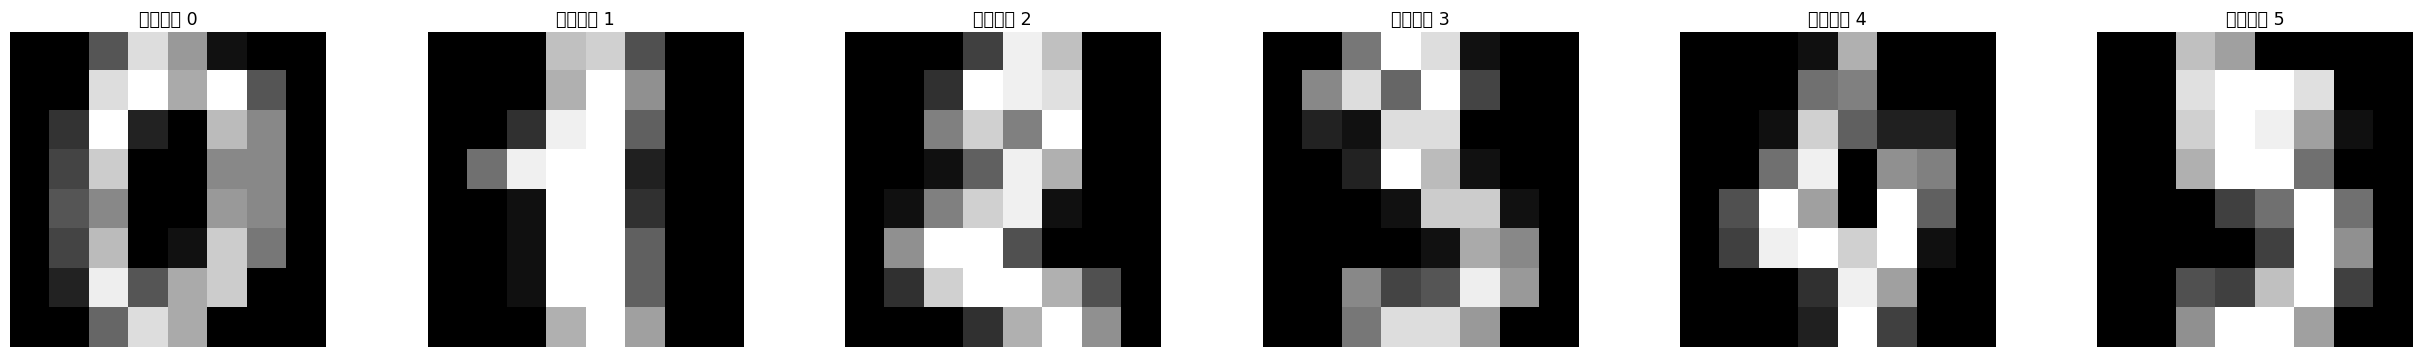

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/04_digits_input.png')

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,confusion_matrix,ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
data=load_digits(); images=data.images.astype(np.float32); labels=data.target
print("输入:",images.shape,"标签:",labels.shape,"范围:",(images.min(),images.max()))
print("第一张图矩阵:\n",images[0]); print("标签:",labels[0])
show_images(list(images[:6]),[f"真实标签 {v}" for v in labels[:6]]); save_figure("04_digits_input")


## 2 分层划分，不把测试集用于选择参数
训练集拟合模型，验证集选择配置，测试集在确定模型后报告。此处演示按样本分层；医疗/同一学生/同一视频等数据需要按患者、身份或序列分组，防止泄漏。


In [3]:
indices=np.arange(len(labels))
train_val,test=train_test_split(indices,test_size=0.2,random_state=42,stratify=labels)
train,val=train_test_split(train_val,test_size=0.25,random_state=42,stratify=labels[train_val])
assert not (set(train)&set(test) or set(train)&set(val) or set(val)&set(test))
print("训练/验证/测试:",len(train),len(val),len(test))
for name,idx in [("train",train),("val",val),("test",test)]: print(name,np.bincount(labels[idx]))


训练/验证/测试: 1077 360 360
train [106 109 107 109 109 109 109 107 104 108]
val [36 37 35 37 36 36 36 36 35 36]
test [36 36 35 37 36 37 36 36 35 36]


## 3 基线：训练、验证选择与测试
用归一化像素训练逻辑回归。归一化常量 16 来自数据定义，不是用测试集估计。


C 0.1 验证accuracy 0.95
C 1.0 验证accuracy 0.9722
C 10.0 验证accuracy 0.975
最终测试准确率: 0.9611


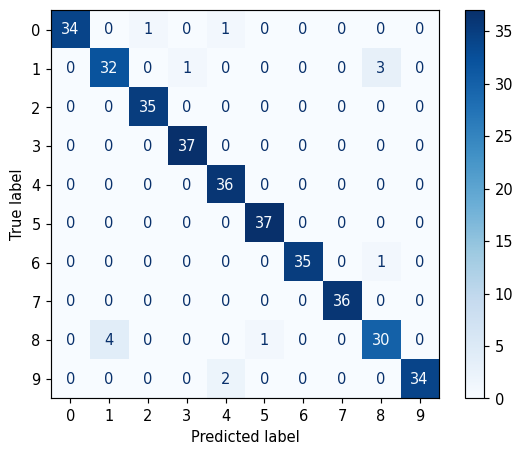

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/04_confusion_matrix.png')

In [4]:
x=images.reshape(len(images),-1)/16
candidates=[]
for c in [0.1,1.0,10.0]:
    model=LogisticRegression(C=c,max_iter=1000).fit(x[train],labels[train])
    score=accuracy_score(labels[val],model.predict(x[val])); candidates.append((score,model,c)); print("C",c,"验证accuracy",round(score,4))
best=max(candidates,key=lambda item:item[0])[1]
pred=best.predict(x[test]); accuracy=accuracy_score(labels[test],pred)
print("最终测试准确率:",round(accuracy,4))
ConfusionMatrixDisplay(confusion_matrix(labels[test],pred)).plot(cmap="Blues"); save_figure("04_confusion_matrix")


## 4 输出与错误分析
概率不是正确性的保证。先看误分类，再考虑增加数据或改变模型。


/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:58: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/course_utils.py:68: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  plt.gcf().savefig(path, dpi=140, bbox_inches='tight', facecolor='white')
/ds1/workspace/CV/cv-beginner-course/cours

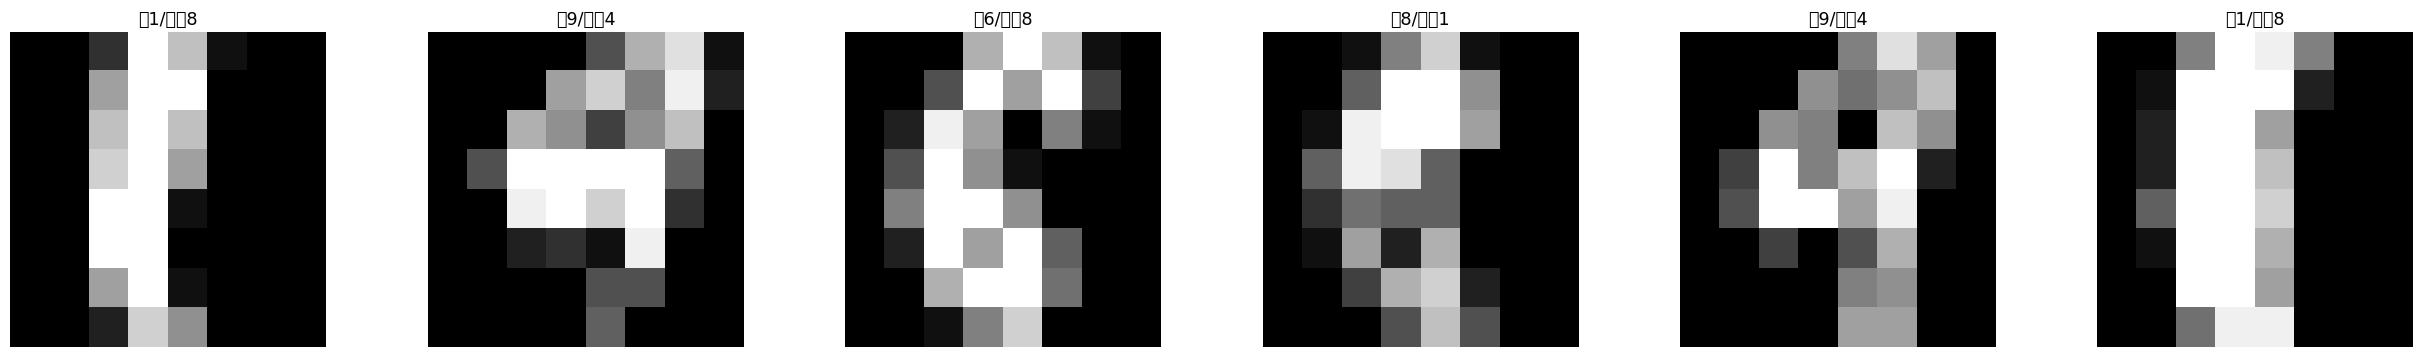

原分布测试准确率: 0.9611111111111111
合成黑白反转测试准确率: 0.0
反转像素矩阵:
 [[1.   1.   0.5  0.25 0.12 0.25 0.81 1.  ]
 [1.   1.   0.25 0.69 1.   0.81 1.   1.  ]
 [1.   1.   0.   0.88 0.75 0.94 1.   1.  ]
 [1.   0.75 0.   0.12 0.25 0.06 0.75 1.  ]
 [1.   1.   0.75 1.   1.   0.5  0.5  1.  ]
 [1.   0.94 1.   1.   1.   0.31 0.69 1.  ]
 [1.   0.62 0.12 0.94 0.88 0.06 0.94 1.  ]
 [1.   1.   0.5  0.12 0.   0.75 1.   1.  ]]


In [5]:
wrong=np.where(pred!=labels[test])[0]
selected=wrong[:6] if len(wrong) else np.arange(6)
show_images([images[test[i]] for i in selected],[f"真{labels[test[i]]}/预测{pred[i]}" for i in selected])
save_figure("04_predictions")
shifted=1-x[test]
print("原分布测试准确率:",accuracy)
print("合成黑白反转测试准确率:",accuracy_score(labels[test],best.predict(shifted)))
print("反转像素矩阵:\n",shifted[0].reshape(8,8).round(2))


## 5 任务与指标对应

|任务|标签/输出|评价与本课程|
|---|---|---|
|分类|类别，N×C logits|Accuracy、混淆矩阵；06|
|检测|类别和边界框|IoU、匹配后的Precision/Recall；07（小样例不宣称COCO mAP）|
|分割|每像素类别|Dice、IoU；08|
|检索|查询与相关集合|Recall@K、AP；09|
|生成|图像分布/条件|样本质量与多样性；10不以小样本声称FID排名|
|描述|词序列|Token/句子准确率；11受控数据|
|超分|配对低清/高清|PSNR；12|
|深度/光流/姿态|连续值/关键点|深度误差、EPE、PCK；13/14/16|

数据清单还应记录：名称、版本、来源、许可、标注、划分、下载大小、隐私限制。本课程素材清单在 assets/SOURCES.json。
练习：增加噪声或旋转，在不改变测试集的前提下改进训练集增强，并保留前后指标。
后续模型索引：05 传统特征、06 CNN、07 检测、08 编码器解码器、10 DDPM、11 CNN+GRU；用任务选择模型，不把模型名混在一张无分类清单。
